# Fraud Dataset — EDA Learning Notebook

**Dataset:** IBM Synthetic Credit Card Transactions (`ealtman2019/credit-card-transactions`, Kaggle)

**Scope of this notebook:** Data understanding and EDA only. No modeling here — the goal is to build a real, defensible understanding of the data before any model gets near it.

**How to use this notebook:** Every section has:
- 🎯 **Goal** — what this step is for
- 💡 **Why it matters** — the reasoning, so you're not just running cells blindly
- code — fully written, ready to run


## 0. Setup

🎯 **Goal:** imports and configuration in one place.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from ydata_profiling import ProfileReport
from IPython.display import FileLink # this is for creating a clickable link to the profile report in the notebook

## these are needed for saving/loading parquet files that are too large for pandas to handle on its own. 
# import pyarrow as pa
# import pyarrow.parquet as pq


sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

RAW_DIR = Path("../data/raw")

TRANSACTIONS_FULL = RAW_DIR / "credit_card_transactions-ibm_v2.csv"
TRANSACTIONS_SAMPLE = RAW_DIR / "User0_credit_card_transactions.csv"
USERS_FILE = RAW_DIR / "sd254_users.csv"
CARDS_FILE = RAW_DIR / "sd254_cards.csv"

# Start with the sample for speed while you're learning the notebook.
# Switch to False once you trust the pipeline, and re-run everything for real numbers.
# Single-user EDA/statistics are NOT representative — treat sample-mode output as a dry run only.
USE_SAMPLE = True

TARGET = "Is Fraud?"


## 1. Load the data

🎯 **Goal:** get the raw file into memory and look at it before touching anything.

💡 **Why it matters:** always look at raw, untouched data first. If you clean before you look, you can't tell whether a "weird" value was a real data quality issue or something you introduced.


In [2]:
path = TRANSACTIONS_FULL
df = pd.read_csv(path)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 24,386,900 rows x 15 columns


,User,Card,Year,Month,Day,Time,Amount,Use Chip,Merchant Name,Merchant City,Merchant State,Zip,MCC,Errors?,Is Fraud?
0,0,0,2002,9,1,06:21,$134.09,Swipe Transaction,3527213246127876953,La Verne,CA,91750.0,5300,NaN,No
1,0,0,2002,9,1,06:42,$38.48,Swipe Transaction,-727612092139916043,Monterey Park,CA,91754.0,5411,NaN,No
2,0,0,2002,9,2,06:22,$120.34,Swipe Transaction,-727612092139916043,Monterey Park,CA,91754.0,5411,NaN,No
3,0,0,2002,9,2,17:45,$128.95,Swipe Transaction,3414527459579106770,Monterey Park,CA,91754.0,5651,NaN,No
4,0,0,2002,9,3,06:23,$104.71,Swipe Transaction,5817218446178736267,La Verne,CA,91750.0,5912,NaN,No


In [3]:
# profile = ProfileReport(df, title= 'Profiling Report', explorative= True)
# profile.to_file('report.html')
# FileLink(r'report.html')

**Figure 1** 
<p align="center">
  <img src="../reports/figures/fig1.png" width="800">
</p>


**Figure 2**
<p align="center">
  <img src="../reports/figures/fig2.png" width="800">
</p>


In [4]:
# df.to_parquet("../data/cache/parquet_df.parquet")


In [5]:
# parquet_df = pd.read_parquet("../data/cache/df_clean.parquet")

In [6]:

df.User.unique()

array([   0,    1,    2, ..., 1997, 1998, 1999], shape=(2000,))

In [7]:
df["User"].value_counts()

User
486     82355
396     80749
332     70010
262     68089
1249    65644
        ...  
457        25
231        21
1367       20
1767       16
1817       15
Name: count, Length: 2000, dtype: int64

In [8]:
# Check how many users have how many rows. 
# This is a good sanity check to see if the data is balanced across users.
user_row_counts = (
    df["User"]
    .value_counts()
    .sort_index()
    #.reset_index()
)

user_row_counts.columns = ["User", "Row_Count"]

user_row_counts

User
0       19963
1        8919
2       41978
3       10117
4       18542
        ...  
1995    14713
1996    18012
1997    21607
1998     5782
1999     4761
Name: count, Length: 2000, dtype: int64

In [9]:
df["User"].value_counts().describe()

count     2000.000000
mean     12193.450000
std      10720.016934
min         15.000000
25%       4008.000000
50%      10860.500000
75%      17425.750000
max      82355.000000
Name: count, dtype: float64

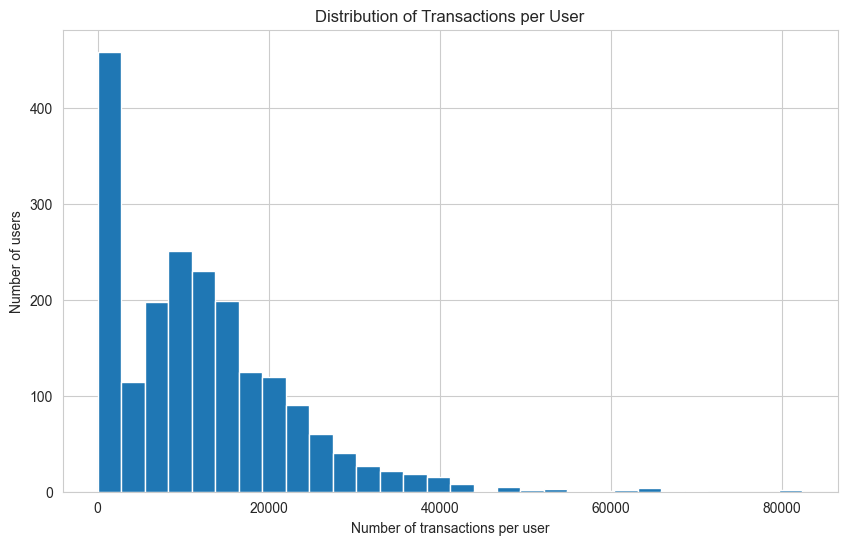

In [10]:
import matplotlib.pyplot as plt

user_counts = df["User"].value_counts()

plt.figure(figsize=(10, 6))
plt.hist(user_counts, bins=30)
plt.xlabel("Number of transactions per user")
plt.ylabel("Number of users")
plt.title("Distribution of Transactions per User")
plt.show()

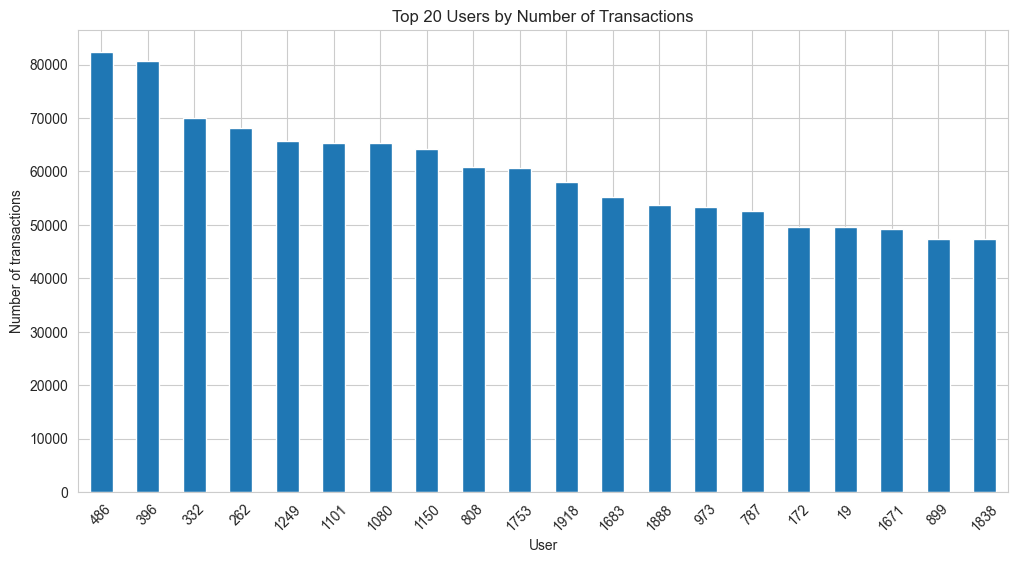

In [11]:
user_counts = df["User"].value_counts().head(20)

plt.figure(figsize=(12, 6))
user_counts.plot(kind="bar")
plt.xlabel("User")
plt.ylabel("Number of transactions")
plt.title("Top 20 Users by Number of Transactions")
plt.xticks(rotation=45)
plt.show()

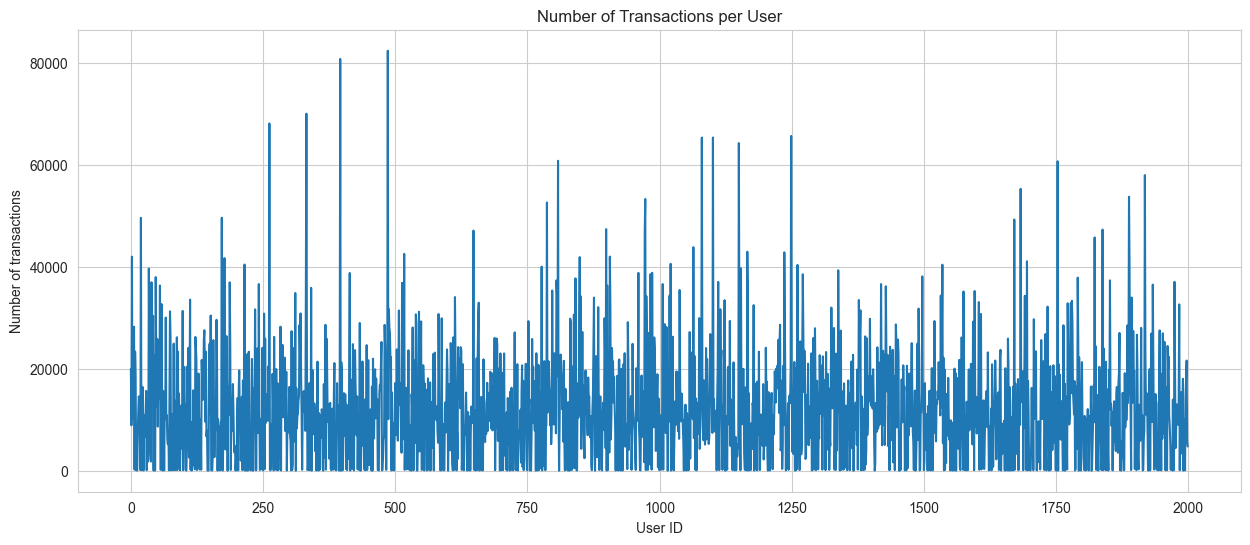

In [12]:
user_counts = df["User"].value_counts().sort_index()

plt.figure(figsize=(15, 6))
user_counts.plot()
plt.xlabel("User ID")
plt.ylabel("Number of transactions")
plt.title("Number of Transactions per User")
plt.show()

In [13]:
df["Is Fraud?"].value_counts()

Is Fraud?
No     24357143
Yes       29757
Name: count, dtype: int64

In [14]:
fraud_by_user = (
    df[df["Is Fraud?"] == 'Yes']
    ["User"]
    .value_counts()
    .sort_index()
)

fraud_by_user

User
0       27
1       33
2       44
3       20
4        2
        ..
1992     1
1993    42
1995    12
1996    50
1997    20
Name: count, Length: 1343, dtype: int64

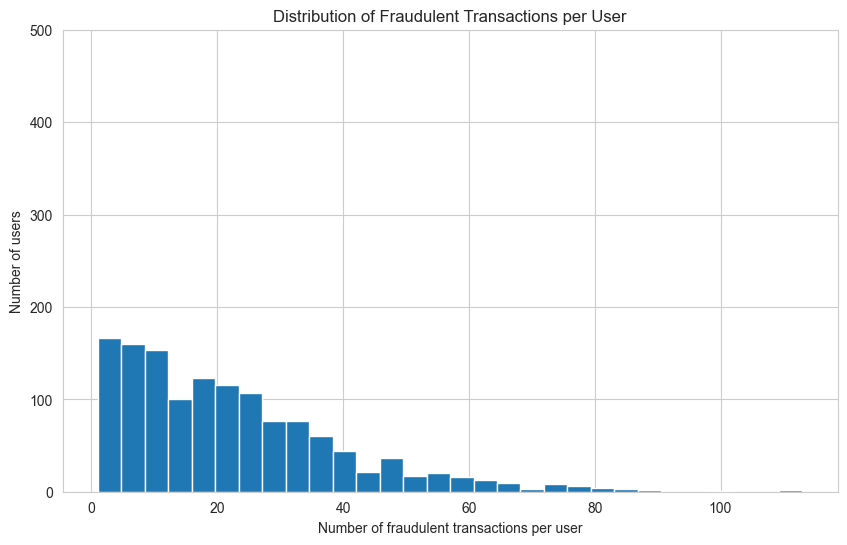

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(fraud_by_user, bins=30)

plt.xlabel("Number of fraudulent transactions per user")
plt.ylabel("Number of users")
plt.title("Distribution of Fraudulent Transactions per User")

plt.ylim(0, 500)
plt.yticks(range(0, 501, 100))

# plt.xlim(0, 80000)
# plt.xticks(range(0, 80001, 10000))

plt.show()

In [16]:
non_fraud_by_user = (
    df[df["Is Fraud?"] == 'No']
    ["User"]
    .value_counts()
    .sort_index()
)

non_fraud_by_user

User
0       19936
1        8886
2       41934
3       10097
4       18540
        ...  
1995    14701
1996    17962
1997    21587
1998     5782
1999     4761
Name: count, Length: 2000, dtype: int64

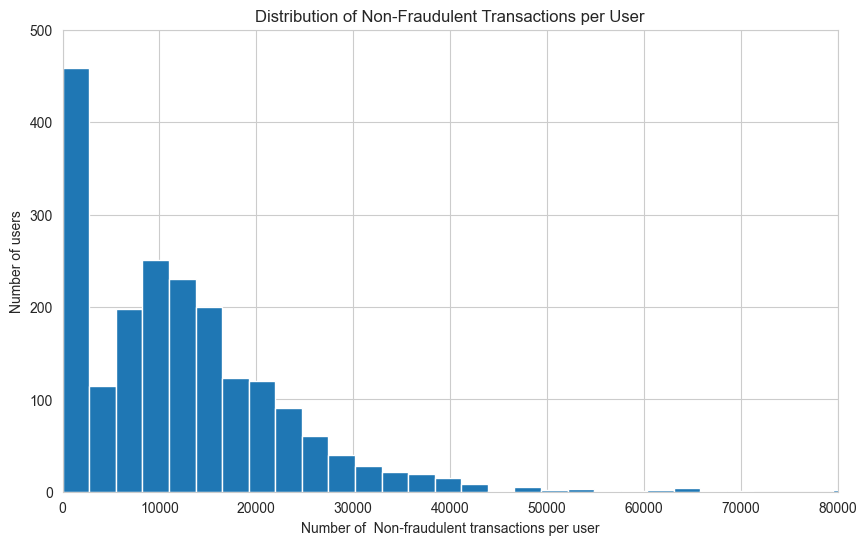

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(non_fraud_by_user, bins=30)

plt.xlabel("Number of  Non-fraudulent transactions per user")
plt.ylabel("Number of users")
plt.title("Distribution of Non-Fraudulent Transactions per User")

plt.ylim(0, 500)
plt.yticks(range(0, 501, 100))

plt.xlim(0, 80000)
plt.xticks(range(0, 80001, 10000))

plt.show()

## 2. Data Quality Assessment

### 2.1 Raw dtypes

🎯 **Goal:** see what Pandas guessed for each column's type, before you fix anything.

💡 **Why it matters:** Pandas infers types by pattern-matching values, not by understanding what the column *means*. A zip code looks numeric to Pandas but is really a label. A `$`-prefixed amount looks like text to Pandas but is really a number. Spotting this mismatch — "numeric-looking ≠ numeric-meaning" — is step one of any real data quality assessment.


In [18]:
print(df.dtypes)
print()
df.info(memory_usage="deep")


User                int64
Card                int64
Year                int64
Month               int64
Day                 int64
Time               object
Amount             object
Use Chip           object
Merchant Name       int64
Merchant City      object
Merchant State     object
Zip               float64
MCC                 int64
Errors?            object
Is Fraud?          object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24386900 entries, 0 to 24386899
Data columns (total 15 columns):
 #   Column          Dtype  
---  ------          -----  
 0   User            int64  
 1   Card            int64  
 2   Year            int64  
 3   Month           int64  
 4   Day             int64  
 5   Time            object 
 6   Amount          object 
 7   Use Chip        object 
 8   Merchant Name   int64  
 9   Merchant City   object 
 10  Merchant State  object 
 11  Zip             float64
 12  MCC             int64  
 13  Errors?         object 
 14  Is Fraud?  

In [19]:
# print(parquet_df.dtypes)
# print()
# parquet_df.info(memory_usage="deep")

### Why that means memory doesn't improve

Parquet's efficiency gains come almost entirely from dtype optimization + compression of repeated categorical values.
If you feed it object columns full of raw Python strings (Time, Amount, Use Chip, etc.) and int64/float64 everywhere, 
Parquet has nothing to optimize — it faithfully stores the same wasteful representation you gave it. 
Parquet is a storage format, not a magic memory reducer. 
It only saves you memory if the DataFrame you feed it already has efficient dtypes (category, int8, datetime64, cleaned numeric Amount), which is the whole reason we built clean_transactions().


**dtype optimization** → makes your pandas DataFrame efficient in RAM

**Parquet** → makes your persisted dataset efficient on disk and generally faster to reload/query

**Figure 3** 
<p align="center">
  <img src="../reports/figures/fig3.png" width="800">
</p>


### 2.2 Fix dtypes + measure the memory impact

💡 **Why it matters:** at 24M rows, dtype choices are the difference between a notebook that runs in seconds and one that runs out of RAM. This is also a legitimate engineering point to make in an interview — quantify it, don't just assert it.


In [20]:
for col in df.columns:
    n = df[col].nunique()
    print(f"{col}: {n} unique values")

User: 2000 unique values
Card: 9 unique values
Year: 30 unique values
Month: 12 unique values
Day: 31 unique values
Time: 1440 unique values
Amount: 98953 unique values
Use Chip: 3 unique values
Merchant Name: 100343 unique values
Merchant City: 13429 unique values
Merchant State: 223 unique values
Zip: 27321 unique values
MCC: 109 unique values
Errors?: 23 unique values
Is Fraud?: 2 unique values


In [21]:
df["Card"].unique().tolist()

[0, 1, 2, 3, 4, 5, 6, 7, 8]

In [22]:
df["Card"].value_counts().sort_index()



Card
0    8696411
1    6493597
2    4305594
3    2790785
4    1309120
5     563097
6     176729
7      46383
8       5184
Name: count, dtype: int64

In [23]:
# how many cards does each user actually have?
df.groupby("User")["Card"].nunique().describe()
# Count: how many users have card data

count    2000.000000
mean        3.069500
std         1.635851
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         9.000000
Name: Card, dtype: float64

### .nunique() vs apply(type).value_counts()
* .nunique() answers "how many different values are there?"
* .apply(type).value_counts() answers "are all these values stored the same way? or they are all the same datatype?"

### They're checking two completely different things:
* **nunique() = cardinality (how many distinct zips)**
* **apply(type).value_counts() = type consistency (is every row actually a float, or is something secretly a string hiding in there)**

In [24]:
print(f"{df["Zip"].nunique()} unique zip codes")

27321 unique zip codes


In [25]:
# this is a sanity check to see if the Zip column is all floats? or if there are any strings or other types mixed in.
df["Zip"].apply(type).value_counts()

Zip
<class 'float'>    24386900
Name: count, dtype: int64

In [26]:
def clean_transactions(df_raw: pd.DataFrame) -> pd.DataFrame:
    """Fix dtypes and parse time fields. Does not drop or impute anything —
    data quality decisions (drop/impute/flag) belong in later, explicit steps,
    not silently inside a cleaning function."""
    d = df_raw.copy()

    # Amount: strip '$' and convert to numeric
    d["Amount"] = d["Amount"].astype(str).str.replace("$", "", regex=False)
    d["Amount"] = pd.to_numeric(d["Amount"], errors="coerce").astype("float32")
    # errors="coerce" means that if the conversion fails (e.g., due to a non-numeric string), 
    # it will set the value to NaN instead of raising an error.

    # Time: keep raw string for now, but also extract Hour/Minute directly
    # (string split is faster than full datetime parsing at this scale)
    d["Time"] = d["Time"].astype(str).str.strip() # .strip() is important because some rows have trailing whitespace, which breaks the split
    d["Hour"] = d["Time"].str.split(":").str[0].astype("int8")
    d["Minute"] = d["Time"].str.split(":").str[1].astype("int8")

    # Build a real datetime column for chronological sorting / time-series work
    d["Transaction Datetime"] = pd.to_datetime(
        d["Year"].astype(str) + "-" +
        d["Month"].astype(str).str.zfill(2) + "-" +
        d["Day"].astype(str).str.zfill(2) + " " + d["Time"],
        errors="coerce"
    )

    # Small-range integers: downcast
    for col in ["User", "Card", "Year", "Month", "Day", "MCC"]:
        if col in d.columns:
            d[col] = pd.to_numeric(d[col], errors="coerce")
            if d[col].dropna().between(0, 127).all():
                d[col] = d[col].astype("int8")
            elif d[col].dropna().between(0, 32767).all():
                d[col] = d[col].astype("int16")
            else:
                d[col] = d[col].astype("int32")

    # Merchant Name is an ID, not a quantity — huge range, keep as int64/category-safe
    if "Merchant Name" in d.columns:
        d["Merchant Name"] = pd.to_numeric(d["Merchant Name"], errors="coerce")

    # Zip is a label, not a number — keep as string to preserve things like leading zeros
    if "Zip" in d.columns:
        d["Zip"] = d["Zip"].astype("Int64").astype(str).replace("<NA>", np.nan)

    # Low-cardinality repeating strings -> category
    for col in ["Use Chip", "Merchant City", "Merchant State", "Errors?", "Is Fraud?"]:
        if col in d.columns:
            d[col] = d[col].astype("category")

    return d


before_mb = df.memory_usage(deep=True).sum() / 1024**2
df_clean = clean_transactions(df)
after_mb = df_clean.memory_usage(deep=True).sum() / 1024**2

print(f"Memory before: {before_mb:,.2f} MB")
print(f"Memory after:  {after_mb:,.2f} MB")
print(f"Reduction:     {(1 - after_mb/before_mb) * 100:.1f}%")
print()
print(df_clean.dtypes)


Memory before: 9,973.93 MB
Memory after:  3,334.95 MB
Reduction:     66.6%

User                             int16
Card                              int8
Year                             int16
Month                             int8
Day                               int8
Time                            object
Amount                         float32
Use Chip                      category
Merchant Name                    int64
Merchant City                 category
Merchant State                category
Zip                             object
MCC                              int16
Errors?                       category
Is Fraud?                     category
Hour                              int8
Minute                            int8
Transaction Datetime    datetime64[ns]
dtype: object


### Caching the cleaned data as Parquet

CSV forces every reload to re-parse text and re-infer types from scratch — on 24.4M rows, that means redoing all the dtype optimization work (int downcasting, category conversion, `$` stripping) every single session.

Saving the **already-cleaned** DataFrame to Parquet preserves dtypes exactly, so future reloads are instant and require no re-cleaning. This only pays off because the DataFrame going in is already optimized — Parquet compresses efficient dtypes well, but doesn't fix inefficient ones on its own.

> **Confirmed earlier:** saving the raw uncleaned data to Parquet gave almost no memory benefit, 9.7GB → 9.5GB.


**Figure 4** 
<p align="center">
  <img src="../reports/figures/fig4.jpg" width="800">
</p>


In [27]:
for col in df_clean.columns:
    n = df_clean[col].nunique()
    print(f"{col}: {n} unique values")

User: 2000 unique values
Card: 9 unique values
Year: 30 unique values
Month: 12 unique values
Day: 31 unique values
Time: 1440 unique values
Amount: 98952 unique values
Use Chip: 3 unique values
Merchant Name: 100343 unique values
Merchant City: 13429 unique values
Merchant State: 223 unique values
Zip: 27321 unique values
MCC: 109 unique values
Errors?: 23 unique values
Is Fraud?: 2 unique values
Hour: 24 unique values
Minute: 60 unique values
Transaction Datetime: 7859684 unique values


### 2.3 Missing values — and whether they're informative

🎯 **Goal:** quantify missingness, then test WHY it's missing rather than just reporting the percentage.

💡 **Why it matters:** the single most common EDA mistake is treating all missing values the same way. A missing `Merchant City` on an online transaction isn't a data error — there's no physical merchant location to log. Dropping or imputing that would destroy real information. The test below checks whether missingness in location fields is *structural* (tied to `Use Chip`) rather than random.

Note: check the exact category labels in `Use Chip` before filtering — don't assume the string is `'Online'`, confirm it first.


In [28]:
print("Use Chip categories:", df_clean["Use Chip"].cat.categories.tolist())

Use Chip categories: ['Chip Transaction', 'Online Transaction', 'Swipe Transaction']


In [29]:
print(df_clean["Use Chip"].value_counts())

Use Chip
Swipe Transaction     15386082
Chip Transaction       6287598
Online Transaction     2713220
Name: count, dtype: int64


In [30]:
df_clean["Errors?"].value_counts(dropna=False).sum

<bound method Series.sum of Errors?
NaN                                                    23998469
Insufficient Balance                                     242783
Bad PIN                                                   58918
Technical Glitch                                          48157
Bad Card Number                                           13321
Bad CVV                                                   10740
Bad Expiration                                            10716
Bad Zipcode                                                2079
Bad PIN,Insufficient Balance                                581
Insufficient Balance,Technical Glitch                       457
Bad PIN,Technical Glitch                                    128
Bad Card Number,Insufficient Balance                        122
Bad CVV,Insufficient Balance                                 89
Bad Expiration,Insufficient Balance                          78
Bad Card Number,Bad CVV                                      60
Bad 

In [31]:
missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_pct": (df_clean.isna().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)

print(missing_summary[missing_summary["missing_count"] > 0])

                missing_count  missing_pct
Errors?              23998469        98.41
Zip                   2878135        11.80
Merchant State        2720821        11.16


In [32]:
# do a crosstab to see if missing Merchant State and Zip are correlated with online transactions
state_na = df_clean["Merchant State"].isna()
zip_na   = df_clean["Zip"].isna()
online   = df_clean["Use Chip"].eq("Online Transaction")

pd.crosstab([state_na, zip_na], online,
            rownames=["state_missing", "zip_missing"], colnames=["online"],
            margins=True)

online                        False     True       All
state_missing zip_missing                             
False         False        21508765        0  21508765
              True           157314        0    157314
True          True             7601  2713220   2720821
All                        21673680  2713220  24386900

In [33]:
online = df_clean["Use Chip"].eq("Online Transaction")
both_missing = df_clean["Merchant State"].isna() & df_clean["Zip"].isna()

print("Online rows:                 ", f"{online.sum():,}")
print("Online rows missing BOTH:    ", f"{(online & both_missing).sum():,}")
print("Offline rows missing BOTH:   ", f"{(~online & both_missing).sum():,}")

Online rows:                  2,713,220
Online rows missing BOTH:     2,713,220
Offline rows missing BOTH:    7,601


In [34]:
online = df_clean["Use Chip"].eq("Online Transaction")

rows = []
for col in ["Merchant City", "Merchant State", "Zip"]:
    miss = df_clean[col].isna()
    n_miss = miss.sum()
    rows.append({
        "column": col,
        "missing (total)": n_miss,
        "missing & online": (miss & online).sum(),
        "missing & offline": (miss & ~online).sum(),
        "% of missing that is online": (miss & online).sum() / n_miss * 100 if n_miss else np.nan,
        "% of online rows missing": (miss & online).sum() / online.sum() * 100,
    })

summary = pd.DataFrame(rows).set_index("column")

summary.style.format({
    "missing (total)": "{:,.0f}",
    "missing & online": "{:,.0f}",
    "missing & offline": "{:,.0f}",
    "% of missing that is online": "{:.1f}%",
    "% of online rows missing": "{:.1f}%",
}, na_rep="n/a")

,missing (total),missing & online,missing & offline,% of missing that is online,% of online rows missing
column,,,,,
Merchant City,0,0,0,n/a,0.0%
Merchant State,"2,720,821","2,713,220","7,601",99.7%,100.0%
Zip,"2,878,135","2,713,220","164,915",94.3%,100.0%


### 2.4 Duplicate transactions

🎯 **Goal:** find exact duplicate rows, and separately, rows that share user/card/amount/merchant/time but might not be byte-identical.

💡 **Why it matters:** not all duplicates mean the same thing. An exact duplicate row is likely a logging/ingestion error. A same-user/card/amount/merchant/timestamp match could be a legitimate retry (e.g. a failed chip read followed by a successful one) — or it could be a sign of rapid repeated card testing, which is itself a fraud pattern. Don't just count them — look at a few and decide which story fits.


In [35]:
exact_dupes = df_clean.duplicated(keep=False).sum()
print(f"Exact duplicate rows: {exact_dupes}")

subset_cols = ["User", "Card", "Amount", "Merchant Name", "Transaction Datetime"]
near_dupes = df_clean.duplicated(subset=subset_cols, keep=False).sum()
print(f"Same user/card/amount/merchant/timestamp: {near_dupes}")

if near_dupes:
    print()
    print("Sample of near-duplicates:")
    display_cols = subset_cols + ["Use Chip", "Errors?", "Is Fraud?"]
    print(df_clean[df_clean.duplicated(subset=subset_cols, keep=False)][display_cols].head(10).to_string(index=False))

Exact duplicate rows: 132
Same user/card/amount/merchant/timestamp: 440

Sample of near-duplicates:
 User  Card  Amount        Merchant Name Transaction Datetime          Use Chip              Errors? Is Fraud?
    9     0    60.0 -4282466774399734331  2012-03-08 07:19:00 Swipe Transaction              Bad PIN        No
    9     0    60.0 -4282466774399734331  2012-03-08 07:19:00 Swipe Transaction                  NaN        No
   13     0   100.0 -4282466774399734331  2015-04-28 06:36:00  Chip Transaction Insufficient Balance        No
   13     0   100.0 -4282466774399734331  2015-04-28 06:36:00  Chip Transaction Insufficient Balance        No
   13     1   100.0 -4282466774399734331  2006-07-19 07:34:00 Swipe Transaction Insufficient Balance        No
   13     1   100.0 -4282466774399734331  2006-07-19 07:34:00 Swipe Transaction Insufficient Balance        No
   13     1   100.0 -4282466774399734331  2006-10-15 07:11:00 Swipe Transaction Insufficient Balance        No
   13     1 

### 2.5 Negative and zero-dollar amounts

🎯 **Goal:** check for amounts that look "invalid" at first glance.

💡 **Why it matters:** in payment data, negative amounts are usually refunds/reversals — a real business event, not an error. Zero-dollar transactions can be authorization/verification checks — and in fraud specifically, $0 auths are a known "card testing" pattern (checking a stolen card is still live before a real charge). Don't drop these without checking what they actually are first.


In [36]:
neg = (df_clean["Amount"] < 0).sum()
zero = (df_clean["Amount"] == 0).sum()

print(f"Negative amounts: {neg} ({neg/len(df_clean)*100:.4f}%)")
print(f"Zero amounts:     {zero} ({zero/len(df_clean)*100:.4f}%)")
print()
print(df_clean["Amount"].describe())
print()

if neg:
    print("Negative-amount examples:")
    print(df_clean.loc[df_clean["Amount"] < 0,
          ["User", "Amount", "Use Chip", "Errors?", "Is Fraud?"]].head(10).to_string(index=False))

if zero:
    print()
    print("Zero-amount examples:")
    print(df_clean.loc[df_clean["Amount"] == 0,
          ["User", "Amount", "Use Chip", "Errors?", "Is Fraud?"]].head(10).to_string(index=False))

Negative amounts: 1244683 (5.1039%)
Zero amounts:     20213 (0.0829%)

count    2.438690e+07
mean     4.363401e+01
std      8.202239e+01
min     -5.000000e+02
25%      9.200000e+00
50%      3.014000e+01
75%      6.506000e+01
max      1.239050e+04
Name: Amount, dtype: float64

Negative-amount examples:
 User  Amount          Use Chip Errors? Is Fraud?
    0   -99.0 Swipe Transaction     NaN        No
    0  -100.0 Swipe Transaction     NaN        No
    0   -99.0 Swipe Transaction     NaN        No
    0   -88.0 Swipe Transaction     NaN        No
    0  -207.0 Swipe Transaction     NaN        No
    0   -57.0 Swipe Transaction     NaN        No
    0   -66.0 Swipe Transaction     NaN        No
    0   -96.0 Swipe Transaction     NaN        No
    0   -91.0 Swipe Transaction     NaN        No
    0   -98.0 Swipe Transaction     NaN        No

Zero-amount examples:
 User  Amount          Use Chip Errors? Is Fraud?
    5     0.0 Swipe Transaction     NaN        No
    5     0.0 Swipe Tran

### 2.6 Class imbalance

🎯 **Goal:** quantify exactly how rare fraud is.

💡 **Why it matters:** this single number determines almost every later modeling decision (why accuracy is useless, why you need PR-AUC not ROC-AUC alone, why you might need class weighting). Get in the habit of stating it two ways — as a percentage AND as a ratio — the ratio is more intuitive to a non-technical reader.


In [37]:
fraud_counts = df_clean[TARGET].value_counts()
fraud_pct = df_clean[TARGET].value_counts(normalize=True) * 100

print(fraud_counts)
print()
if "Yes" in fraud_counts.index:
    print(f"Fraud rate: {fraud_pct['Yes']:.4f}%")
    print(f"Ratio: 1 fraud case per {int(fraud_counts['No'] / fraud_counts['Yes']):,} legitimate transactions")
else:
    print("No fraud cases in this slice of data — expected if using a very small sample.")

Is Fraud?
No     24357143
Yes       29757
Name: count, dtype: int64

Fraud rate: 0.1220%
Ratio: 1 fraud case per 818 legitimate transactions


## 3. Univariate EDA

### 3.1 Amount distribution

🎯 **Goal:** understand the shape of transaction amounts.

💡 **Why it matters:** transaction amounts in almost any payments dataset are heavily right-skewed (lots of small purchases, a long tail of large ones). A raw histogram will look uninformative — a log transform usually reveals the real shape.


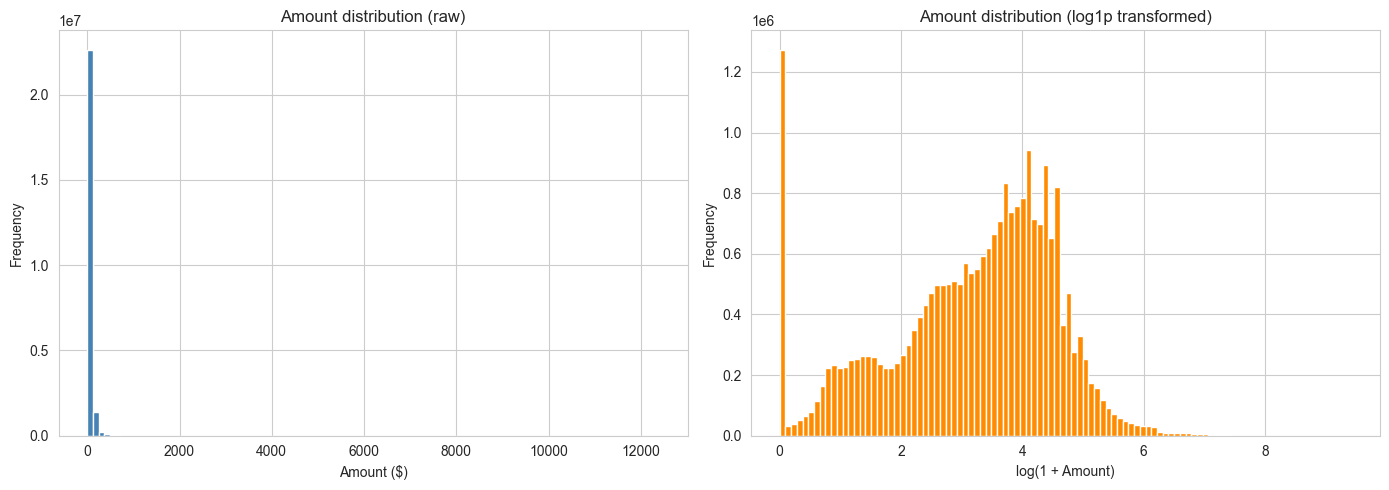

count    2.438690e+07
mean     4.363401e+01
std      8.202239e+01
min     -5.000000e+02
25%      9.200000e+00
50%      3.014000e+01
75%      6.506000e+01
max      1.239050e+04
Name: Amount, dtype: float64


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_clean["Amount"].clip(lower=0).plot(kind="hist", bins=100, ax=axes[0], color="steelblue")
axes[0].set_title("Amount distribution (raw)")
axes[0].set_xlabel("Amount ($)")

np.log1p(df_clean["Amount"].clip(lower=0)).plot(kind="hist", bins=100, ax=axes[1], color="darkorange")
axes[1].set_title("Amount distribution (log1p transformed)")
axes[1].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

print(df_clean["Amount"].describe())


### 3.2 Payment method (`Use Chip`) distribution

🎯 **Goal:** see the split between swipe / chip / online transactions.


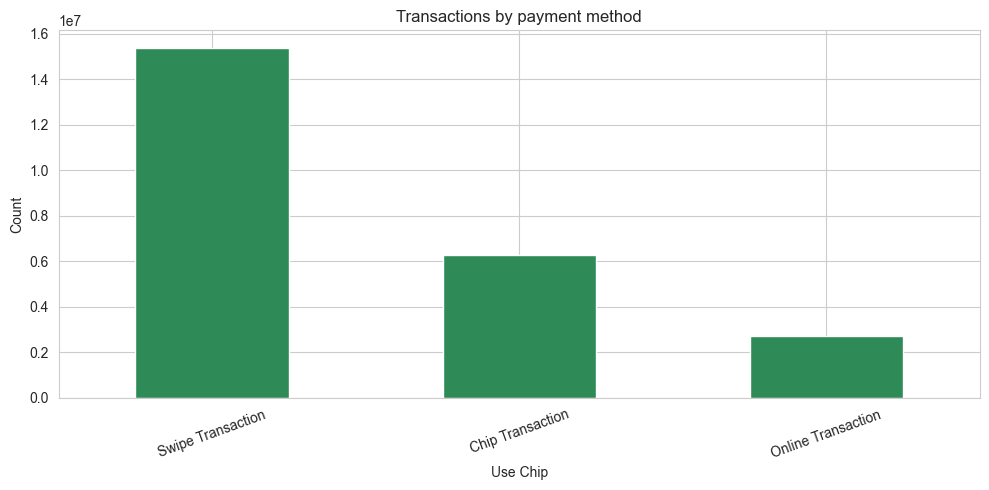

Use Chip
Swipe Transaction     15386082
Chip Transaction       6287598
Online Transaction     2713220
Name: count, dtype: int64
Use Chip
Swipe Transaction     63.09
Chip Transaction      25.78
Online Transaction    11.13
Name: count, dtype: float64


In [39]:
counts = df_clean["Use Chip"].value_counts()
counts.plot(kind="bar", color="seagreen")
plt.title("Transactions by payment method")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print(counts)
print((counts / counts.sum() * 100).round(2))


### 3.3 Merchant Category Codes (MCC) — top categories by volume

🎯 **Goal:** see which merchant types generate the most transactions, before looking at fraud rate by MCC later.

💡 **Why it matters:** volume and risk are different questions. This cell answers "where does most spending happen" — section 5.4 later answers "where is fraud concentrated." Keep them separate.


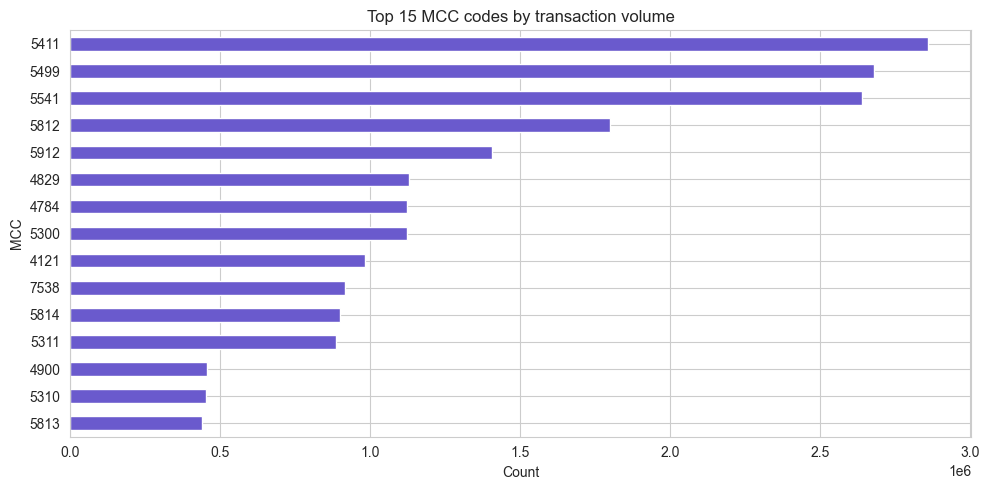

MCC
5411    2860738
5499    2680609
5541    2638982
5812    1797920
5912    1407636
4829    1129061
4784    1124291
5300    1123037
4121     981523
7538     914630
5814     900255
5311     885720
4900     457616
5310     454107
5813     439018
Name: count, dtype: int64


In [40]:
top_mcc = df_clean["MCC"].value_counts().head(15)
top_mcc.plot(kind="barh", color="slateblue")
plt.title("Top 15 MCC codes by transaction volume")
plt.xlabel("Count")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
print(top_mcc)

## 4. Temporal EDA

🎯 **Goal:** find cyclical patterns — payment activity is rarely uniform across hours/days/months.


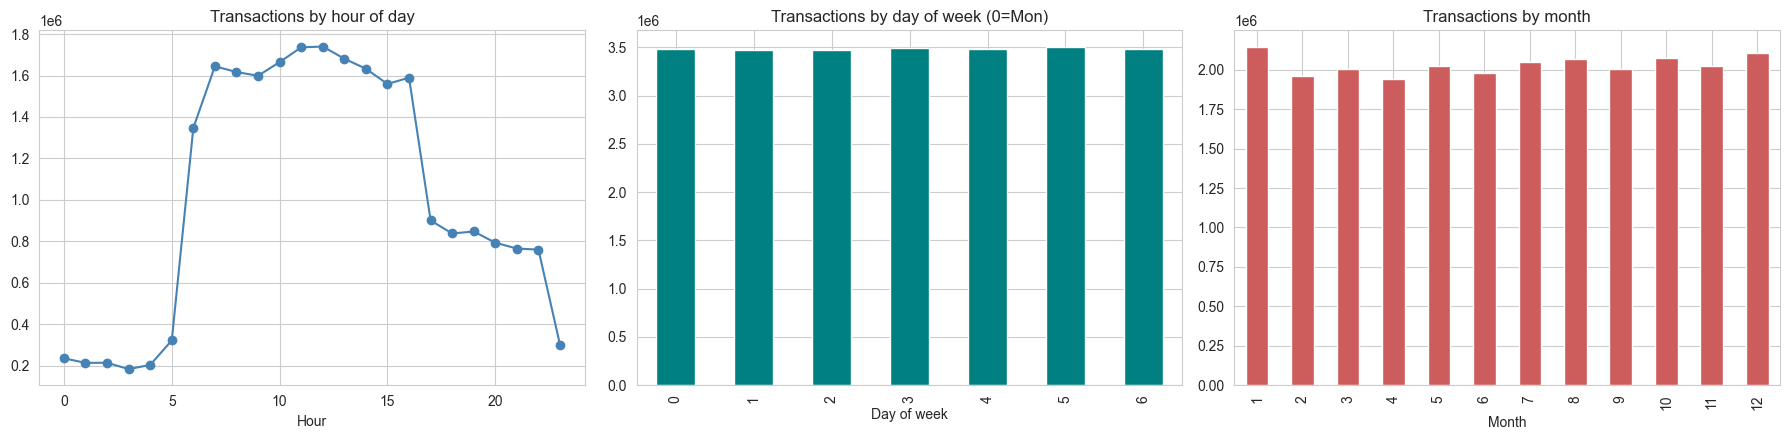

In [41]:
df_clean["DayOfWeek"] = df_clean["Transaction Datetime"].dt.dayofweek  # 0=Monday
df_clean["MonthOfYear"] = df_clean["Transaction Datetime"].dt.month

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

df_clean["Hour"].value_counts().sort_index().plot(kind="line", ax=axes[0], marker="o", color="steelblue")
axes[0].set_title("Transactions by hour of day")
axes[0].set_xlabel("Hour")

df_clean["DayOfWeek"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Transactions by day of week (0=Mon)")
axes[1].set_xlabel("Day of week")

df_clean["MonthOfYear"].value_counts().sort_index().plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("Transactions by month")
axes[2].set_xlabel("Month")

plt.tight_layout()
plt.show()


## 5. Fraud-focused EDA

This is the core of the notebook — everything above sets up understanding of the data; this section looks specifically at how fraud differs from normal activity.

### 5.1 Fraud rate by hour of day


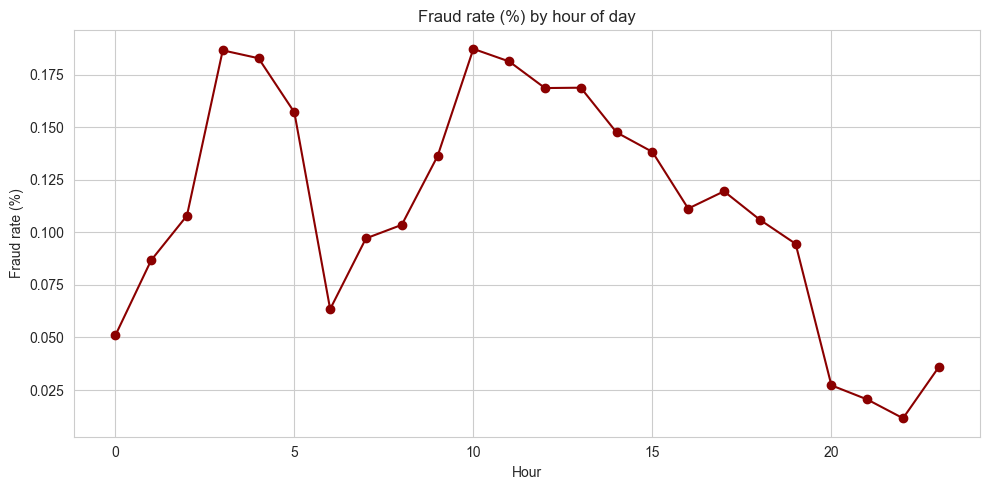

Hour
0     0.051
1     0.087
2     0.108
3     0.187
4     0.183
5     0.157
6     0.063
7     0.097
8     0.104
9     0.136
10    0.187
11    0.181
12    0.169
13    0.169
14    0.147
15    0.138
16    0.111
17    0.119
18    0.106
19    0.095
20    0.027
21    0.021
22    0.012
23    0.036
dtype: float64


In [42]:
fraud_by_hour = df_clean.groupby(["Hour", TARGET]).size().unstack(fill_value=0)
if "Yes" in fraud_by_hour.columns:
    fraud_rate_by_hour = fraud_by_hour["Yes"] / fraud_by_hour.sum(axis=1) * 100
    fraud_rate_by_hour.plot(kind="line", marker="o", color="darkred")
    plt.title("Fraud rate (%) by hour of day")
    plt.xlabel("Hour")
    plt.ylabel("Fraud rate (%)")
    plt.tight_layout()
    plt.show()
    print(fraud_rate_by_hour.round(3))
else:
    print("No fraud cases present in this slice — switch to the full dataset to see this pattern.")


### 5.2 Fraud rate by payment method


In [43]:
fraud_by_method = pd.crosstab(df_clean["Use Chip"], df_clean[TARGET])
fraud_by_method["total"] = fraud_by_method.sum(axis=1)
if "Yes" in fraud_by_method.columns:
    fraud_by_method["fraud_rate_pct"] = (fraud_by_method["Yes"] / fraud_by_method["total"] * 100).round(3)
print(fraud_by_method.sort_values("fraud_rate_pct", ascending=False) if "fraud_rate_pct" in fraud_by_method else fraud_by_method)


Is Fraud?                 No    Yes     total  fraud_rate_pct
Use Chip                                                     
Online Transaction   2694871  18349   2713220           0.676
Chip Transaction     6282762   4836   6287598           0.077
Swipe Transaction   15379510   6572  15386082           0.043


### 5.3 Amount: fraud vs. legitimate transactions


                count    mean     std    min    25%    50%     75%       max
Is Fraud?                                                                   
No         24357143.0   43.55   81.74 -500.0   9.20  30.11   65.00  12390.50
Yes           29757.0  108.59  201.17 -500.0  18.36  71.02  150.13   5694.44


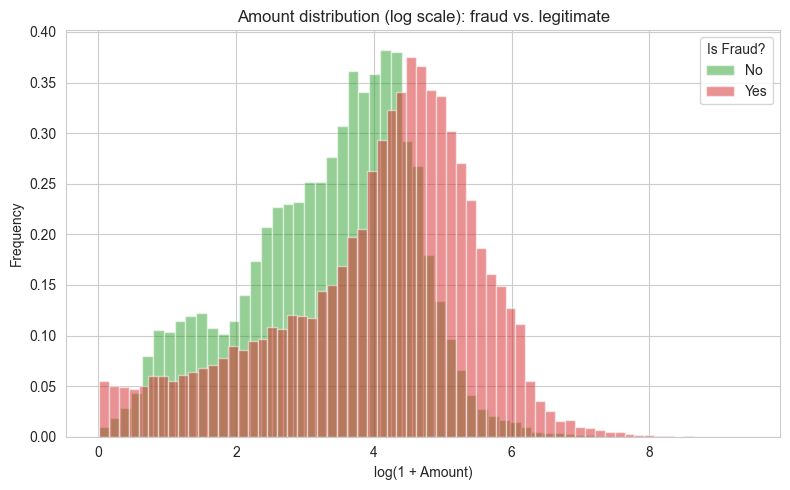

In [44]:
summary = df_clean.groupby(TARGET)["Amount"].describe().round(2)
print(summary)

fig, ax = plt.subplots(figsize=(8, 5))
for label, color in [("No", "#2ca02c"), ("Yes", "#d62728")]:
    if label in df_clean[TARGET].cat.categories:
        subset = df_clean.loc[df_clean[TARGET] == label, "Amount"]
        subset = subset[subset > 0]  # log scale needs positive values
        np.log1p(subset).plot(kind="hist", bins=60, alpha=0.5, ax=ax, label=label, color=color, density=True)
ax.set_title("Amount distribution (log scale): fraud vs. legitimate")
ax.set_xlabel("log(1 + Amount)")
ax.legend(title="Is Fraud?")
plt.tight_layout()
plt.show()


### 5.4 Fraud rate by merchant category (MCC) — with a sample-size guardrail

💡 **Why it matters:** MCC codes with only 1-2 transactions can show a "100% fraud rate" purely by chance. That's noise, not a finding. Always report volume alongside rate, and filter out categories too small to trust.


In [45]:
MIN_TRANSACTIONS = 30  # adjust based on dataset size (higher threshold needed for full data)

mcc_summary = (
    df_clean.groupby("MCC")
    .agg(transactions=("MCC", "size"),
         fraud_rate_pct=(TARGET, lambda s: (s == "Yes").mean() * 100))
    .reset_index()
    .query("transactions >= @MIN_TRANSACTIONS")
    .sort_values("fraud_rate_pct", ascending=False)
)
print(mcc_summary.head(15).round(3).to_string(index=False))


 MCC  transactions  fraud_rate_pct
4411           634          50.000
5733           496          25.605
5045          5013           9.376
3006           702           8.405
3144           632           8.386
3008           714           7.003
5732         12593           6.694
3007           666           6.156
3075           666           6.006
5094          9444           6.004
5816          5003           5.956
3005           729           5.898
5712          7149           5.847
3009           739           5.819
4112          4151           3.830


### 5.5 Prior transaction errors vs. fraud

💡 **Why it matters:** a declined or error-flagged transaction followed by a fraud attempt could indicate a tester probing a stolen card. This checks whether `Errors?` co-occurs with fraud more than chance would predict.


In [46]:
has_error = df_clean["Errors?"].notna()
cross = pd.crosstab(has_error, df_clean[TARGET])
cross["total"] = cross.sum(axis=1)
if "Yes" in cross.columns:
    cross["fraud_rate_pct"] = (cross["Yes"] / cross["total"] * 100).round(3)
print(cross)


Is Fraud?        No    Yes     total  fraud_rate_pct
Errors?                                             
False      23969998  28471  23998469           0.119
True         387145   1286    388431           0.331


## 6. Relational EDA — bring in users and cards

🎯 **Goal:** this is the differentiator most fraud-detection portfolio projects skip. The transactions file alone can't tell you if fraud correlates with *who the customer is* (age, income, credit score) or *what card they're using* (type, brand). Joining in the linked tables lets you ask that.

💡 **Why it matters:** relational feature engineering (joining across normalized tables) is a real skill gap between "ran a notebook on one CSV" and "understands how production data actually looks." Fintechs rarely have one flat file — they have normalized systems you have to join.

Note: check the actual column names in your downloaded files first — the ones below are typical for this dataset, but confirm before assuming.


In [47]:
users = pd.read_csv(USERS_FILE)
cards = pd.read_csv(CARDS_FILE)

print("Users columns:", users.columns.tolist())
print("Users shape:", users.shape)
print()
print("Cards columns:", cards.columns.tolist())
print("Cards shape:", cards.shape)


Users columns: ['Person', 'Current Age', 'Retirement Age', 'Birth Year', 'Birth Month', 'Gender', 'Address', 'Apartment', 'City', 'State', 'Zipcode', 'Latitude', 'Longitude', 'Per Capita Income - Zipcode', 'Yearly Income - Person', 'Total Debt', 'FICO Score', 'Num Credit Cards']
Users shape: (2000, 18)

Cards columns: ['User', 'CARD INDEX', 'Card Brand', 'Card Type', 'Card Number', 'Expires', 'CVV', 'Has Chip', 'Cards Issued', 'Credit Limit', 'Acct Open Date', 'Year PIN last Changed', 'Card on Dark Web']
Cards shape: (6146, 13)


In [48]:
print("df_clean columns:")
print(df_clean.columns.tolist())

print("\nusers columns:")
print(users.columns.tolist())

print("\ncards columns:")
print(cards.columns.tolist())

df_clean columns:
['User', 'Card', 'Year', 'Month', 'Day', 'Time', 'Amount', 'Use Chip', 'Merchant Name', 'Merchant City', 'Merchant State', 'Zip', 'MCC', 'Errors?', 'Is Fraud?', 'Hour', 'Minute', 'Transaction Datetime', 'DayOfWeek', 'MonthOfYear']

users columns:
['Person', 'Current Age', 'Retirement Age', 'Birth Year', 'Birth Month', 'Gender', 'Address', 'Apartment', 'City', 'State', 'Zipcode', 'Latitude', 'Longitude', 'Per Capita Income - Zipcode', 'Yearly Income - Person', 'Total Debt', 'FICO Score', 'Num Credit Cards']

cards columns:
['User', 'CARD INDEX', 'Card Brand', 'Card Type', 'Card Number', 'Expires', 'CVV', 'Has Chip', 'Cards Issued', 'Credit Limit', 'Acct Open Date', 'Year PIN last Changed', 'Card on Dark Web']


In [49]:
print("Unique Users in df_clean:", df_clean["User"].nunique())
print("Unique Persons in users:", users["Person"].nunique())
print("Unique Users in cards:", cards["User"].nunique())

Unique Users in df_clean: 2000
Unique Persons in users: 1993
Unique Users in cards: 2000


In [50]:
cards = cards.rename(columns={"CARD INDEX": "Card"})
users = users.reset_index().rename(columns={"index": "User"})

user_cols = ["User", "Current Age", "Gender", "Yearly Income - Person",
             "Total Debt", "FICO Score", "Num Credit Cards"]
card_cols = ["User", "Card", "Card Brand", "Card Type", "Has Chip",
             "Credit Limit", "Card on Dark Web"]   # drop Card Number / CVV: PII, no value
users, cards = users[user_cols], cards[card_cols]

# Credit Limit, Income, Debt probably arrive as "$"-strings, so check dtypes and reuse the Amount cleaning
cards = cards.astype({"User": "int16", "Card": "int8"})

df_full = (df_clean
    .merge(users, on="User", how="left", validate="many_to_one")
    .merge(cards, on=["User", "Card"], how="left", validate="many_to_one", indicator=True))

assert len(df_full) == len(df_clean)          # a left join must not change row count
print(df_full["_merge"].value_counts())       # real unmatched check

_merge
both          24386900
left_only            0
right_only           0
Name: count, dtype: int64


### 6.1 Fraud rate by credit score band

💡 **Why it matters:** don't just eyeball a correlation — bucket into bands so the pattern (if any) is readable, and think about *why* before concluding causation. Lower credit score correlating with fraud could mean riskier customers are targeted more, OR it could be confounded by something else (e.g. account age, transaction volume). State the finding, then note the confound — don't overclaim.


In [51]:
score_col = "FICO Score"  # confirm this matches your actual users.csv column name

if score_col in df_full.columns:
    df_full["credit_score_band"] = pd.cut(
        df_full[score_col],
        bins=[0, 580, 670, 740, 800, 850],
        labels=["Poor (<580)", "Fair (580-670)", "Good (670-740)", "Very Good (740-800)", "Excellent (800+)"]
    )
    band_summary = (
        df_full.groupby("credit_score_band")[TARGET]
        .apply(lambda s: (s == "Yes").mean() * 100)
    )
    band_counts = df_full["credit_score_band"].value_counts()
    print(pd.DataFrame({"fraud_rate_pct": band_summary.round(3), "n_transactions": band_counts}))
else:
    print(f"Column '{score_col}' not found — check df_full.columns and update score_col above.")


                     fraud_rate_pct  n_transactions
credit_score_band                                  
Poor (<580)                   0.078          950651
Fair (580-670)                0.114         3911360
Good (670-740)                0.123        11436806
Very Good (740-800)           0.134         5951933
Excellent (800+)              0.120         2136150


### 6.2 Fraud rate by card type / brand


In [52]:
for col in ["Card Type", "Card Brand"]:
    if col in df_full.columns:
        summary = (
            df_full.groupby(col)[TARGET]
            .apply(lambda s: (s == "Yes").mean() * 100)
            .sort_values(ascending=False)
        )
        counts = df_full[col].value_counts()
        print(f"--- {col} ---")
        print(pd.DataFrame({"fraud_rate_pct": summary.round(3), "n_transactions": counts}))
        print()
    else:
        print(f"Column '{col}' not found — check df_full.columns.")


--- Card Type ---
                 fraud_rate_pct  n_transactions
Card Type                                      
Credit                    0.131         7673643
Debit                     0.111        15059468
Debit (Prepaid)           0.174         1653789

--- Card Brand ---
            fraud_rate_pct  n_transactions
Card Brand                                
Amex                 0.129         1602563
Discover             0.146          716333
Mastercard           0.121        13092130
Visa                 0.121         8975874



## 7. Geographic EDA

🎯 **Goal:** see whether fraud is geographically concentrated.


In [53]:
geo_summary = (
    df_clean.dropna(subset=["Merchant State"])
    .groupby("Merchant State")[TARGET]
    .agg(transactions="size", fraud_rate_pct=lambda s: (s == "Yes").mean() * 100)
)
MIN_STATE_TXNS = 30
geo_summary = geo_summary[geo_summary["transactions"] >= MIN_STATE_TXNS].sort_values("fraud_rate_pct", ascending=False)
print(geo_summary.round(3).head(15))


                transactions  fraud_rate_pct
Merchant State                              
Tuvalu                    59         100.000
Algeria                  654          96.177
Haiti                    446          84.081
Fiji                      40          80.000
Nigeria                  233          61.373
Turkey                   472          54.449
Italy                   8730          53.631
Japan                   3955           1.239
Mexico                 47152           0.577
India                   3482           0.144
OH                    895970           0.098
AK                     18301           0.044
NE                     96747           0.033
HI                    140180           0.033
CA                   2591830           0.029


### python -m jupyter nbconvert --to html "cluade_fraud_eda_learning_notebook.ipynb"

# 8. Next Steps: Modeling Plan

The EDA above was deliberately scoped to understanding the data. Before any model is trained, here is what the findings imply and the plan that follows from them.

## What the EDA tells me

| Finding | Implication for modeling |
|---|---|
| Fraud is 0.122% of transactions (1:818) | Accuracy is meaningless; use PR-AUC and recall at a fixed precision. Handle imbalance with class weights. |
| Online is 11% of volume but ~62% of fraud | Payment method is a strong feature. Check other signals within each payment type. |
| Foreign merchant states show 50–100% fraud vs. ~0.03% domestic | Likely a synthetic-data shortcut. Must be tested with an ablation so results aren't inflated. |
| Structural missingness (State/Zip null for online) | Don't impute. Encode explicitly (`is_online`, `is_international`). |
| User attributes are snapshots, not point-in-time | Possible time leakage. Treat time-varying user features with caution. |
| Credit score barely discriminates | Don't expect large gains from user-level features. |

## Phase 1: Data preparation and split

- **Chronological split** (train → validation → test), not random. Fraud patterns and payment mix drift over time, and a random split would be optimistic. Cutoffs will be chosen so every split contains enough fraud cases.
- **All preprocessing is fit on the training period only** (encoders, scalers, any target statistics), then applied to validation and test.
- **Feature set:** amount (with a sign-preserving transform and a refund flag), hour, payment method, MCC, error flag, international flag, and per-card behavioral features built from past transactions only.
- **High-cardinality columns** (merchant, zip, city) use frequency or native categorical encoding, not one-hot.
- **Excluded for leakage risk:** `Card on Dark Web` (likely discovered after the fact) and any post-transaction information.

### Imbalance handling

Primary approach: class weighting and decision-threshold tuning on the validation set. If more is needed, random undersampling of the majority class (applied to the training period only). 
I considered NearMiss and SMOTE but would not use them as defaults here: distance-based resampling needs a meaningful scaled numeric feature space, which this mixed, high-cardinality data does not provide, it is costly at 24M rows, and resampling to balance distorts probability calibration. All evaluation is done on the original, unresampled class distribution.

## Phase 2: Baseline

A **regularized logistic regression** with class weights comes first.

*Why:* it sets the reference level. If a complex model can't clearly beat it, the complexity isn't justified. It is also interpretable, fast, and a useful sanity check on the feature pipeline.

## Phase 3: Gradient-boosted trees

Train **LightGBM or XGBoost**.

*Why:* tabular fraud data with mixed types, non-linear interactions and missing values is where boosted trees typically perform best, and they need no scaling and handle missing values natively.

## Phase 4: Tuning

- Hyperparameter search (e.g. Optuna) with **time-aware validation**, never touching the test set.
- Tune the main levers: tree depth, learning rate, number of trees, regularization, and class weighting.
- Choose the decision threshold on the validation set, based on a realistic alert budget or precision target.

*Why after the models are chosen:* tuning a model before comparing it against the baseline makes the comparison unfair. Every model gets the same split, the same metric and the same threshold rule.

## Phase 5: Ablations and robustness

- Train with and without `Merchant State` to measure how much the geographic shortcut inflates results.
- Train with and without the user-snapshot features to measure the leakage risk.
- Report performance by payment method and by year, to check that results aren't driven by one segment.

## Phase 6: Final evaluation

- Score the **untouched test set once**, at the validation-chosen threshold.
- Report PR-AUC, recall at fixed precision, and precision at a fixed alert volume, with confidence intervals (bootstrap by user, since transactions from one user are not independent).

## Phase 7: Interpretation with SHAP

- Compute **TreeSHAP on a stratified sample of held-out data** (including fraud cases), not on training data.
- *Purpose:* (1) detect shortcut features, (2) debug false positives and false negatives, (3) explain flagged transactions.
- SHAP describes model behavior, not causation, and credit is split unpredictably among correlated features (e.g. state, zip, online flag). I'll cross-check with permutation importance and the ablations above.

## Limitations to keep in mind

- This is **synthetic data**. Patterns reflect the generator, so results won't transfer directly to production fraud.
- Offline metrics assume features are available at scoring time; this needs confirming for each feature in a real deployment.
- Fraud labels may be delayed in production, which this dataset doesn't capture.